In [7]:
import evidently
print(evidently.__version__)
import json, numpy as np, pandas as pd
from scipy.stats import ks_2samp
from pathlib import Path



0.7.23


In [8]:

csv_path = Path("data/creditcard.csv")
if not csv_path.exists():
    csv_path = Path("../data/creditcard.csv")
df = pd.read_csv(csv_path).sort_values('Time').reset_index(drop=True)
H = 3600
MONITOR = ['Amount', 'V17', 'V14', 'V12', 'V10', 'V11', 'V4', 'V3', 'V1', 'V28']

windows = {f'{a}-{a+6}h': df[(df.Time >= a*H) & (df.Time < (a+6)*H)] for a in [24, 30, 36, 42]}
matched = {f'{a}-{a+6}h': df[(df.Time >= (a-24)*H) & (df.Time < (a-18)*H)] for a in [24, 30, 36, 42]}

def psi(ref_s, cur_s, bins=10):
    edges = np.unique(np.quantile(ref_s, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref_s, edges)[0] / len(ref_s)
    c = np.histogram(cur_s, edges)[0] / len(cur_s)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return np.sum((c - r) * np.log(c / r))

In [10]:
#evidently report
ref_s = matched['42-48h'][MONITOR].sample(20000, random_state=42)
cur_s = windows['42-48h'][MONITOR].sample(min(20000, len(windows['42-48h'])), random_state=42)

try:   # new API (0.7+)
    from evidently import Report, Dataset, DataDefinition
    from evidently.presets import DataDriftPreset
    dd = DataDefinition(numerical_columns=MONITOR)
    ref_ds = Dataset.from_pandas(ref_s, data_definition=dd)
    cur_ds = Dataset.from_pandas(cur_s, data_definition=dd)
    snap = Report([DataDriftPreset()]).run(cur_ds, ref_ds)
except ImportError:   # legacy API (0.4.x)
    from evidently.report import Report
    from evidently.metric_preset import DataDriftPreset
    snap = Report(metrics=[DataDriftPreset()])
    snap.run(reference_data=ref_s, current_data=cur_s)

report_dir = Path("reports")
if not report_dir.is_dir():
    report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)
report_path = report_dir / "evidently_drift_report.html"
snap.save_html(str(report_path))
print(f"saved: {report_path.resolve()}")

saved: C:\Users\HP\Desktop\fraud detection\fraud-detection-project\reports\evidently_drift_report.html


In [14]:
def status(p): return 'significant' if p >= 0.25 else 'moderate' if p >= 0.1 else 'stable'

def build_summary(ref, cur, label):
    rows = []
    for f in MONITOR:
        p = float(psi(ref[f], cur[f])); k = float(ks_2samp(ref[f], cur[f]).statistic)
        rows.append({'feature': f, 'psi': round(p, 3), 'ks': round(k, 3), 'status': status(p)})
    rows.sort(key=lambda r: -r['psi'])
    sig = [r for r in rows if r['status'] == 'significant']
    share = len(sig) / len(rows)
    overall = 'ALERT' if share >= 0.3 else 'WARNING' if sig else 'OK'
    top = ', '.join(f"{r['feature']} ({r['psi']:.2f})" for r in sig[:3])
    text = (f"{len(sig)} of {len(rows)} monitored features show significant drift "
            f"(PSI >= 0.25) in {label}" + (f", led by {top}." if sig else "."))
    return {'window': label, 'n_reference': len(ref), 'n_current': len(cur),
            'overall_status': overall, 'n_significant': len(sig),
            'share_significant': round(share, 2), 'summary': text, 'features': rows}

summary = {
    'reference': 'Same hours of Day 1 (matched-hour reference)',
    'thresholds': {'psi_moderate': 0.1, 'psi_significant': 0.25},
    'windows': {k: build_summary(matched[k], windows[k], k) for k in windows},
}
json.dump(summary, open(report_dir / 'drift_summary.json', 'w'), indent=2)

for k, v in summary['windows'].items():
    print(k, v['overall_status'], '-', v['summary'])

24-30h ALERT - 4 of 10 monitored features show significant drift (PSI >= 0.25) in 24-30h, led by V1 (1.59), V3 (1.29), V28 (1.00).
30-36h ALERT - 4 of 10 monitored features show significant drift (PSI >= 0.25) in 30-36h, led by V1 (1.58), V3 (1.38), V28 (1.13).
36-42h ALERT - 4 of 10 monitored features show significant drift (PSI >= 0.25) in 36-42h, led by V1 (1.52), V3 (1.50), V28 (0.99).
42-48h ALERT - 5 of 10 monitored features show significant drift (PSI >= 0.25) in 42-48h, led by V1 (1.62), V3 (1.46), V28 (1.07).


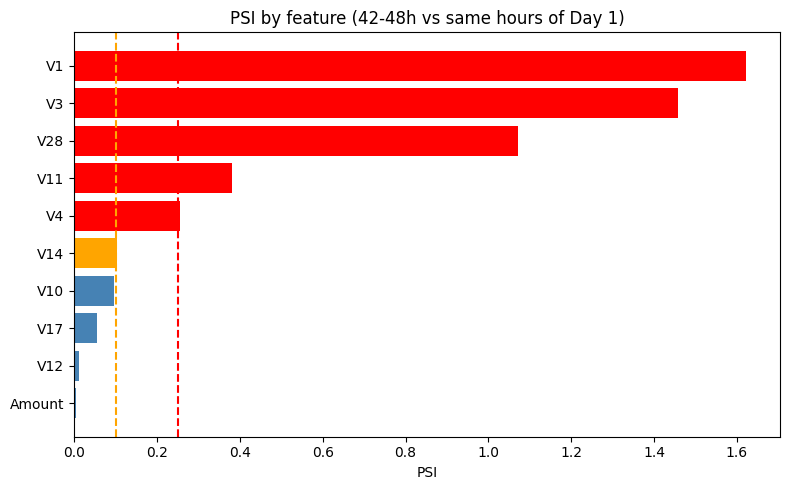

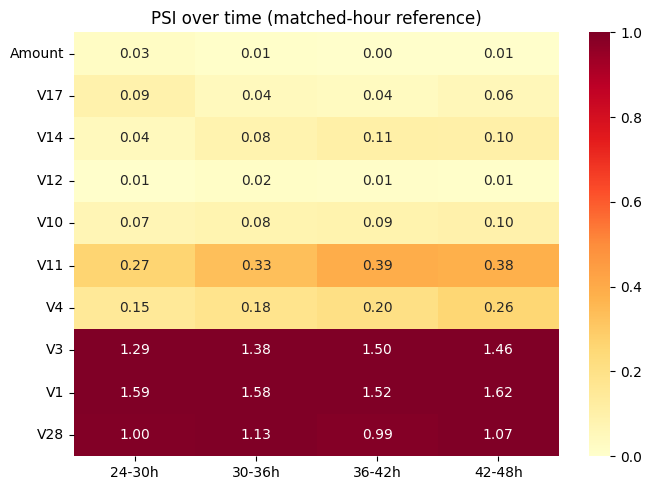

In [13]:
import matplotlib.pyplot as plt, seaborn as sns

d = pd.DataFrame(summary['windows']['42-48h']['features']).sort_values('psi')
colors = d.status.map({'significant': 'red', 'moderate': 'orange', 'stable': 'steelblue'})
plt.figure(figsize=(8, 5))
plt.barh(d.feature, d.psi, color=colors)
plt.axvline(0.1, ls='--', c='orange'); plt.axvline(0.25, ls='--', c='red')
plt.xlabel('PSI'); plt.title('PSI by feature (42-48h vs same hours of Day 1)')
plt.tight_layout(); plt.savefig(report_dir / 'drift_psi_bar.png', dpi=150); plt.show()

heat = pd.DataFrame({k: {r['feature']: r['psi'] for r in v['features']}
                     for k, v in summary['windows'].items()}).loc[MONITOR]
plt.figure(figsize=(7, 5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1)
plt.title('PSI over time (matched-hour reference)')
plt.tight_layout(); plt.savefig(report_dir / 'drift_psi_heatmap.png', dpi=150); plt.show()